In [2]:
import torch
from torch import nn

In [ ]:
# weight 와 bias 확인
x = torch.randn(100, 3)
layer = nn.Linear(3,5)
print(x.shape)
print(layer)
print(layer(x).shape)
print(layer.weight) # 랜덤한 (5,3)의 초기 weight
print(layer.bias)   # 랜덤한 (5,)의 초기 bias

torch.Size([100, 3])
Linear(in_features=3, out_features=5, bias=True)
torch.Size([100, 5])
Parameter containing:
tensor([[ 0.0354, -0.0745, -0.1777],
        [ 0.3244,  0.2154,  0.2995],
        [ 0.4088, -0.2105, -0.0251],
        [-0.5199, -0.0683, -0.3517],
        [-0.4521, -0.4691, -0.2395]], requires_grad=True)
Parameter containing:
tensor([-0.1519,  0.3948,  0.5121, -0.2413,  0.3805], requires_grad=True)


In [6]:
x = torch.randn(2,5)
layer = nn.ReLU()   # 음수값은 0으로 변환
print(x)
print(layer(x))

tensor([[-0.6824, -0.1570, -0.1249,  0.1138,  0.7525],
        [-1.5683, -0.2501, -0.1093,  2.1004, -1.5321]])
tensor([[0.0000, 0.0000, 0.0000, 0.1138, 0.7525],
        [0.0000, 0.0000, 0.0000, 2.1004, 0.0000]])


In [12]:
# 초기 weight와 bias가 랜덤이 아닌 layer
layer = nn.BatchNorm1d(3)   # 표준편차가 1이고 평균이 0인 표준화
print(layer.weight)
print(layer.bias)

x = torch.randn(5,3)
print(x)
print(layer(x))
print(layer(x).mean(dim=0)) # 평균이 0임을 확인
print(layer(x).std(dim=0, unbiased=False))  # False(모평균: 뮤 사용), True(표본평균: x-bar 사용)

Parameter containing:
tensor([1., 1., 1.], requires_grad=True)
Parameter containing:
tensor([0., 0., 0.], requires_grad=True)
tensor([[ 0.0078,  0.5958, -1.5803],
        [ 0.9293, -1.1207, -2.1141],
        [ 0.0319,  0.9168, -0.3692],
        [ 0.2030,  0.5602, -2.9336],
        [ 0.9874, -0.1688, -0.7790]])
tensor([[-0.9738,  0.6009, -0.0273],
        [ 1.1422, -1.7477, -0.6082],
        [-0.9185,  1.0400,  1.2907],
        [-0.5255,  0.5521, -1.5000],
        [ 1.2756, -0.4453,  0.8447]], grad_fn=<NativeBatchNormBackward0>)
tensor([ 2.3842e-08,  0.0000e+00, -4.7684e-08], grad_fn=<MeanBackward1>)
tensor([1.0000, 1.0000, 1.0000], grad_fn=<StdBackward0>)


In [15]:
layer = nn.LayerNorm(3)
print(layer.weight)
print(layer.bias)

x = torch.randn(5,3)
print(x)
print(layer(x))
print(layer(x).mean(dim=1))     # layerNorm에서는 dim=1
print(layer(x).std(dim=1, unbiased=False))

Parameter containing:
tensor([1., 1., 1.], requires_grad=True)
Parameter containing:
tensor([0., 0., 0.], requires_grad=True)
tensor([[ 1.8664,  0.1898,  0.8578],
        [ 0.7250, -0.6832, -0.3425],
        [-0.3544, -0.6630,  0.7245],
        [-0.8206, -0.4710, -0.8909],
        [ 1.2869,  1.8308, -2.6762]])
tensor([[ 1.2988, -1.1340, -0.1648],
        [ 1.3757, -0.9718, -0.4039],
        [-0.4317, -0.9504,  1.3821],
        [-0.5069,  1.3966, -0.8897],
        [ 0.5674,  0.8382, -1.4055]], grad_fn=<NativeLayerNormBackward0>)
tensor([ 5.9605e-08, -1.9868e-08,  0.0000e+00, -5.9605e-08, -7.9473e-08],
       grad_fn=<MeanBackward1>)
tensor([1.0000, 1.0000, 1.0000, 0.9999, 1.0000], grad_fn=<StdBackward0>)


In [17]:
layer = nn.BatchNorm2d(3)
print(layer.weight)
print(layer.bias)

x = torch.randn(5,3,32,32)
print(layer(x).mean(dim=(0,2,3)))   # 각 채널별 평균
# dim은 몬티홀의 문제처럼 구하고 싶은 차원의 번호만 제외하는 방식이었군요
print(layer(x).std(dim=(0,2,3), unbiased=False))

Parameter containing:
tensor([1., 1., 1.], requires_grad=True)
Parameter containing:
tensor([0., 0., 0.], requires_grad=True)
tensor([-1.4901e-09, -3.7253e-10,  7.4506e-10], grad_fn=<MeanBackward1>)
tensor([1.0000, 1.0000, 1.0000], grad_fn=<StdBackward0>)


In [18]:
import torch
from torch import nn, optim
from torch.utils.data import DataLoader, TensorDataset
from torchvision import transforms, datasets
import matplotlib.pyplot as plt
import numpy as np
import os
device = 'cuda' if torch.cuda.is_available() else 'cpu'

In [19]:
BATCH_SIZE = 32
LR = 1e-3
EPOCH = 5
criterion = nn.CrossEntropyLoss()
new_model_train = True

model_type = 'CNN_deep'
dataset = 'CIFAR10'

save_dir = 'results'
os.makedirs(save_dir, exist_ok=True)

save_model_path = f'{save_dir}/{model_type}_{dataset}.pt'

In [ ]:
transform_train = transforms.Compose([
    # ----------- 이미지 size 및 영역 조절 ---------------
    # transforms.Resize(size=(20,20)),    # 보간법(NOTE interpolation)에 따른 픽셀 값 계산
    # transforms.CenterCrop(size=(20,20,)),   # 가운데를 중심으로 외곽을 잘라냄
    # transforms.RandomCrop(size=(20,20)),    # random한 위치를 중심으로 외곽을 자름
    # # 추가 기준 (Anti-aliasing): 이미지를 축소할 때 픽셀이 뭉개지거나 물결무늬(Moire)가 생기는 것을 막기 위해 
    # # antialias=True가 기본 적용 
    # # 이 경우 축소 비율에 맞춰 주변 픽셀들을 먼저 부드럽게 블러(가우시안 필터 등) 처리한 뒤 위 보간법을 적용
    # transforms.Pad(6),  # 원본 사이즈를 유지하기 위해 패드size 만큼의 검은색 테두리 생성

    # ----------- 조건부 이미지 변환 ---------------------
    # transforms.RandomApply(
    #     nn.ModuleList([
    #         transforms.CenterCrop(size=(20,20)),
    #         transforms.Pad(6)
    #     ]), p = 0.5 # 50% 의 확률로 centercrop과 pad 적용
    # ),

    # transforms.RandomResizedCrop(
    #     size= (32, 32),     # 최종 이미지 크기
    #     scale= (0.3, 1),    # 원본 이미지 면적의 30% ~ 100% 범위를 crop
    #     ratio=(0.3, 1.7)    # crop 영역의 가로/세로 비율 범위
    # ),

    # ------------ 색상 및 밝기 조절 --------------------
    # transforms.RandomGrayscale(p=.5),
    # transforms.ColorJitter(
    #     brightness=0.3, # 밝기
    #     contrast= 0.3,  # 대비
    #     saturation=0.5, # 채도
    #     hue= 0.15       # 색조
    # ),
    # transforms.RandomAutocontrast(p=.5),    # 자동으로 명암 대비를 높이는 효과
    # transforms.RandomEqualize(p=0.5),   # 각 채널의 히스토그램을 개별적으로 처리, 평활화(특정 밝기 이미지의 대비 강조)
    transforms.RandomInvert(p=0.5),     # 색상 반전
    transforms.ToTensor()
    # 내가 정의한 함수가 있다면 ToTensor() 다음에 삽입
])
transform_test = transforms.ToTensor()

train_DS = datasets.CIFAR10(root='data', train=True, transform=transform_train, download=True)
test_DS = datasets.CIFAR10(root='data', train=False, transform=transform_test, download=True)

train_DL = DataLoader(train_DS, batch_size= BATCH_SIZE, shuffle=True)
test_DL = DataLoader(test_DS, batch_size=BATCH_SIZE, shuffle=True)

image size= torch.Size([3, 32, 32])
image size= torch.Size([3, 32, 32])


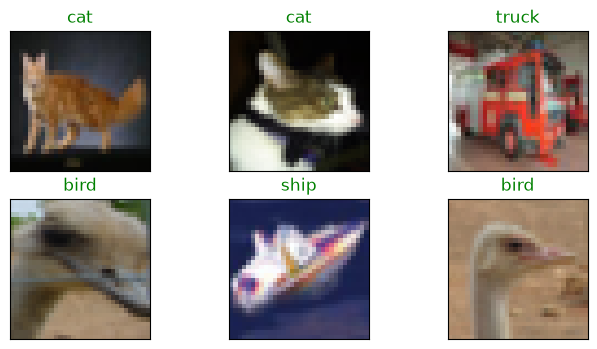

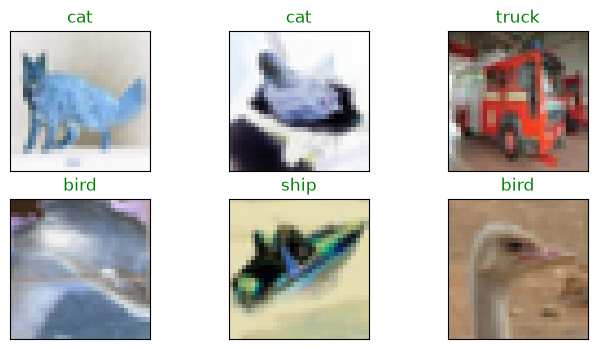

In [69]:
from PIL import Image   # Python Image Library/ Image = numpy array 이미지변환

def im_plot(x_numpy, y_batch, transform):  # 호출할 때 transform.compose의 변환이 실행됨
    plt.figure(figsize=(8,4))
    for idx in range(6):
        im = Image.fromarray(x_numpy[idx])
        im = transform(im)

        plt.subplot(2,3, idx+1, xticks=[], yticks=[])
        plt.imshow(im.permute(1,2,0))
        true_class = test_DS.classes[y_batch[idx]]
        plt.title(true_class, color='g')
    print(f'image size= {im.shape}')

idx = torch.randint(0,10000,(6,))
x_batch = test_DS.data[idx]
target = torch.tensor(test_DS.targets)

y_batch = target[idx]
im_plot(x_batch, y_batch, transform_test)   # 원본(32,32)
im_plot(x_batch, y_batch, transform_train)  # Resize(20,20)